## 1. Instalação dos pacotes necessários

In [20]:
!pip install pandas scikit-learn tensorflow

## 2. Importar as bibliotecas necessárias

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras import Input

## 3. Carregamento e Visualização dos Dados

In [22]:
df = pd.read_csv('/content/bank-full.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Preparação e limpeza de dados

In [23]:
# Separar variáveis independentes (X) e a variável alvo (y)
X = df.drop('y', axis=1)
y = df['y'].map({'yes': 1, 'no': 0})

# Identificar colunas categóricas e numéricas
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

# Pré-processamento com OneHotEncoder e StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

## 5. Divisão dos dados em teste e treino

In [24]:
# Separar em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Total de registos: {len(X)}')
print(f'Treino: {len(X_train)} registos')
print(f'Teste: {len(X_test)} registos')

# Pré-processamento
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

Total de registos: 45211
Treino: 36168 registos
Teste: 9043 registos


## 6. Criação das redes neuronais artificiais

In [25]:
# Modelo de Rede Neural com camada Input explícita
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# Compilar o modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 32)             │         1,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,921 (7.50 KB)

 Trainable params: 1,921 (7.50 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Treinamento do modelo de dados

In [26]:
# Treinar modelo
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8919 - loss: 0.2827 - val_accuracy: 0.9028 - val_loss: 0.2186
Epoch 2/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8994 - loss: 0.2183 - val_accuracy: 0.9043 - val_loss: 0.2147
Epoch 3/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9053 - loss: 0.2121 - val_accuracy: 0.9052 - val_loss: 0.2098
Epoch 4/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9056 - loss: 0.2035 - val_accuracy: 0.9039 - val_loss: 0.2122
Epoch 5/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9067 - loss: 0.2053 - val_accuracy: 0.9066 - val_loss: 0.2055
Epoch 6/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9087 - loss: 0.2025 - val_accuracy: 0.9049 - val_loss: 0.2042
Epoch 7/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9081 - loss: 0.2013 - val_accuracy: 0.9053 - val_loss: 0.2034
Epoch 8/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9105 - loss: 0.1949 - val_accuracy: 0.

## 8. Avaliação do modelo

In [28]:
# Prever com dados de teste
y_pred = (model.predict(X_test) > 0.5).astype("int32")

# Avaliação
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[[7671  281]
 [ 562  529]]
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      7952
           1       0.65      0.48      0.56      1091

    accuracy                           0.91      9043
   macro avg       0.79      0.72      0.75      9043
weighted avg       0.90      0.91      0.90      9043



## 9. Matriz de confusão com heatmap

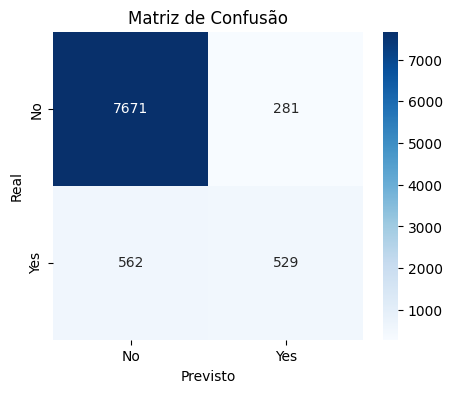

In [29]:
# Matriz de confusão com visualização
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

Nesta matriz de confusão estamos a prever a variável y, para entendermos se o cliente aceitou ou não aderir á campanha de marketing e pelo que podemos observar é muito provavel que a grande maioria dos clientes irá recusar participar enquanto que mesmo aqueles que aceitam participar provavelmente são falsos positivos.
Sendo assim apenas uma minoria seria na verdade verdadeiros positivos.

## 10. Acurácia e Loss

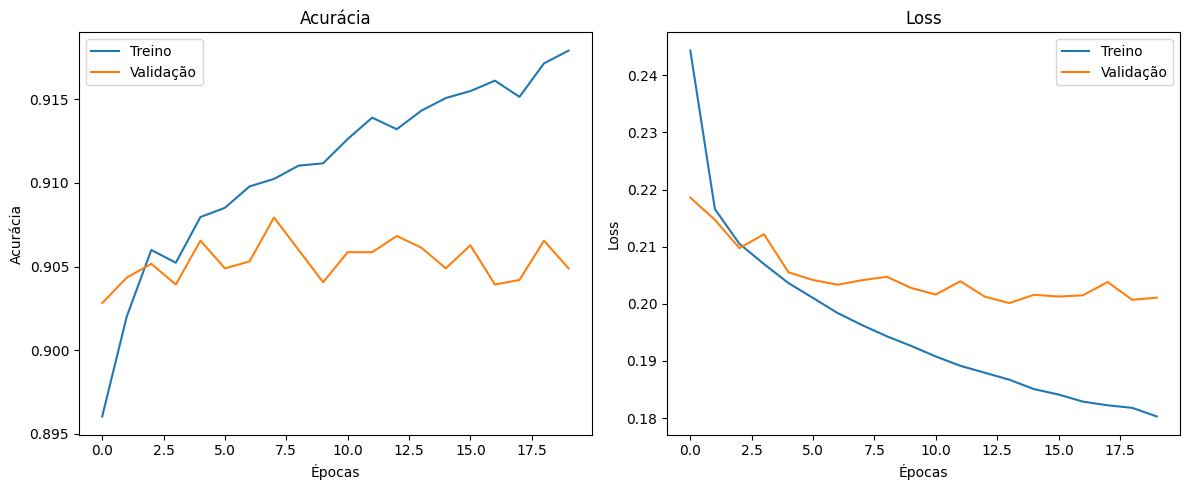

In [30]:
# Gráfico de accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')
plt.title('Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()

# Gráfico de loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')
plt.title('Loss')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 11. Simulação do modelo com um novo caso

In [31]:
new_case = X.iloc[0:1]

# Pré-processar o novo caso
new_case_processed = preprocessor.transform(new_case)

# Prever com o modelo treinado
prediction = model.predict(new_case_processed)

# Converter a previsão para uma classe binária (0 ou 1)
predicted_class = (prediction > 0.5).astype("int32")

print(f'Previsão para o novo caso: {prediction[0][0]:.4f}')
print(f'Classe prevista (0=No, 1=Yes): {predicted_class[0][0]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Previsão para o novo caso: 0.0115
Classe prevista (0=No, 1=Yes): 0
